# Stage 2: Events and matched days

**Project:** Do Price Signals Cut Household Demand? (Team Megamind, MAS course, AIT)
**Stage owner:** Javed (Ahmad Jawid Fedayi) · **Hands off to:** Saniah (Stage 3, scores)

This notebook turns the 2013 price schedule (`Tariffs.xlsx`) into the four tables Stage 3 needs. It follows `docs/decisions.md` §4–5 and the file formats in `BLUEPRINT.md` §7 exactly.

| Output | What it holds | Used by |
|---|---|---|
| `results/events.csv` | One row per High or Low event: when it starts, how long it lasts, and its features | Stage 3 (scoring), Stage 6 (regression) |
| `results/normal_days.csv` | The days whose 48 half-hours are all Normal price | Stage 3, Stage 4 (distribution fit) |
| `results/matched_days.csv` | For each event, every usable comparison day, as a shift of *k* days (\|k\| ≤ 21) | Stage 3, Stage 4 (simulation) |
| `results/matched_counts.csv` | How many matched days each event has within ±14 and ±21 | Stage 3, report (exclusions) |

**It does not touch any electricity readings**, so it is safe to run before the results gate.

**How to run:** put `Tariffs.xlsx` in `data/raw/` and run all cells, from the repository root or from this folder. Takes a few seconds. Needs only `pandas`, `numpy`, `openpyxl` and `matplotlib`.

## 1. Setup: paths and the fixed rules

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

# Paths. The notebook looks for Tariffs.xlsx in data/raw/ under the current folder or its parent,
# so it works from the repository root or from a subfolder of it.
CANDIDATES = [Path.cwd(), Path.cwd().parent]
ROOT = next((p for p in CANDIDATES if (p / "data" / "raw" / "Tariffs.xlsx").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Put Tariffs.xlsx in data/raw/ (under the repository root) and run again.")
TARIFF_FILE = ROOT / "data" / "raw" / "Tariffs.xlsx"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

# Fixed rules (docs/decisions.md §4–5). Do not change these after Stage 0 without a dated entry under "Changes".
YEAR_START = pd.Timestamp("2013-01-01 00:00:00")
N_SLOTS = 365 * 48                       # 17,520 half-hours; slot 0 = 00:00–00:30 on 1 Jan 2013
BANK_HOLIDAYS_2013 = {pd.Timestamp(d).date() for d in [
    "2013-01-01", "2013-03-29", "2013-04-01", "2013-05-06",
    "2013-05-27", "2013-08-26", "2013-12-25", "2013-12-26"]}   # England; treated as weekend days
GRID_HOURS = {23, 2, 5, 8, 11, 14, 17, 20}                     # the 3-hour grid events normally follow
EVENING_START_HOURS = {17, 20}
WINTER_MONTHS = {10, 11, 12, 1, 2, 3}
MAX_SHIFT = 21          # matched days are stored up to ±21 (sensitivity run A)
MAIN_WINDOW = 14        # main analysis uses ±14
MIN_MATCHED = 3         # events with fewer matched days are dropped

print("Tariff file:", TARIFF_FILE)
print("Results go to:", RESULTS)

Tariff file: /home/claude/deliver/Javed - Stage 2/data/raw/Tariffs.xlsx
Results go to: /home/claude/deliver/Javed - Stage 2/results


## 2. Load the price schedule and check it

The file has one row per half-hour of 2013 (a timestamp and `High`, `Low` or `Normal`). It uses the same fixed GMT clock as the meters, so no daylight-saving shift is applied. Each row gets a **slot** number: its position in the year, 0 to 17,519.

In [2]:
def day_type(d):
    # "weekend" for Saturday, Sunday or a 2013 England bank holiday, else "weekday".
    d = pd.Timestamp(d)
    return "weekend" if d.dayofweek >= 5 or d.date() in BANK_HOLIDAYS_2013 else "weekday"


def load_tariffs(path):
    t = pd.read_excel(path, sheet_name=0)              # Sheet2 in the file is empty
    t.columns = [str(c).strip() for c in t.columns]
    t = t.rename(columns={t.columns[0]: "time", t.columns[1]: "price"})
    t["time"] = pd.to_datetime(t["time"])
    t["price"] = t["price"].astype(str).str.strip()  # guards against "High " with a trailing space
    t = t.sort_values("time").reset_index(drop=True)
    t["slot"] = ((t["time"] - YEAR_START) / pd.Timedelta(minutes=30)).round().astype(int)
    assert len(t) == N_SLOTS, f"expected {N_SLOTS} half-hours, found {len(t)}"
    assert (t["slot"].to_numpy() == np.arange(N_SLOTS)).all(), "gaps or repeats in the timestamps"
    assert set(t["price"]) == {"High", "Low", "Normal"}, f"unexpected prices: {set(t['price'])}"
    return t


tariffs = load_tariffs(TARIFF_FILE)
price = tariffs["price"].to_numpy()
print(f"{len(tariffs):,} half-hours, {tariffs.time.min()} to {tariffs.time.max()}, no gaps")
print(tariffs["price"].value_counts().to_string())

17,520 half-hours, 2013-01-01 00:00:00 to 2013-12-31 23:30:00, no gaps
price
Normal    15072
Low        1660
High        788


## 3. Events → `results/events.csv`

An **event** is a run of consecutive half-hours with the same non-Normal price. Reading the year in order, a new run starts whenever the price changes; every High or Low run is one event.

| Column | Meaning |
|---|---|
| `event_id` | `H` or `L` plus the event's position among all events in the year, from 000 (so IDs are not consecutive within a type) |
| `start`, `end` | When the event begins and finishes (e.g. 17:00 and 23:00), GMT |
| `first_slot`, `n_slots` | First half-hour's slot number and the number of half-hours; the event covers `first_slot … first_slot + n_slots − 1` |
| `hours` | `n_slots / 2` |
| `day_type` | `weekday` or `weekend` (Sat, Sun or bank holiday), from the **start** date |
| `off_grid` | True if the start or end is not on the 3-hour grid (23, 02, 05 … 20 h) |
| `low_before` | 1 if the half-hour just before the event is Low-priced |
| `evening` | 1 if the event starts at 17:00 or 20:00 |
| `month`, `winter` | Start month; `winter` = 1 for October–March |

In [3]:
def build_events(tariffs):
    price = tariffs["price"].to_numpy()
    new_run = np.r_[True, price[1:] != price[:-1]]
    run_starts = np.flatnonzero(new_run)
    run_lengths = np.diff(np.r_[run_starts, len(price)])
    rows = [(price[s], int(s), int(n)) for s, n in zip(run_starts, run_lengths) if price[s] != "Normal"]
    ev = pd.DataFrame(rows, columns=["tariff", "first_slot", "n_slots"])

    ev["event_id"] = [("H" if p == "High" else "L") + f"{i:03d}" for i, p in enumerate(ev["tariff"])]
    ev["start"] = YEAR_START + pd.to_timedelta(ev["first_slot"] * 30, unit="min")
    ev["end"] = ev["start"] + pd.to_timedelta(ev["n_slots"] * 30, unit="min")
    ev["hours"] = ev["n_slots"] / 2
    ev["day_type"] = ev["start"].map(day_type)

    def on_grid(ts):
        return (ts.dt.minute == 0) & ts.dt.hour.isin(GRID_HOURS)

    ev["off_grid"] = ~(on_grid(ev["start"]) & on_grid(ev["end"]))
    ev["low_before"] = [int(s > 0 and price[s - 1] == "Low") for s in ev["first_slot"]]
    ev["evening"] = ((ev["start"].dt.minute == 0) & ev["start"].dt.hour.isin(EVENING_START_HOURS)).astype(int)
    ev["month"] = ev["start"].dt.month
    ev["winter"] = ev["month"].isin(WINTER_MONTHS).astype(int)
    return ev[["event_id", "tariff", "start", "first_slot", "n_slots", "end", "hours",
               "day_type", "off_grid", "low_before", "evening", "month", "winter"]]


events = build_events(tariffs)
events.to_csv(RESULTS / "events.csv", index=False)

print(events["tariff"].value_counts().to_string(), "\n")
print("High event lengths (hours: count):",
      events.query("tariff == 'High'")["hours"].value_counts().sort_index().to_dict())
print("Off-grid events:")
print(events.loc[events["off_grid"], ["event_id", "tariff", "start", "end", "hours"]].to_string(index=False))
events.head(8)

tariff
Low     92
High    69 

High event lengths (hours: count): {3.0: 26, 4.0: 1, 6.0: 34, 12.0: 7, 24.0: 1}
Off-grid events:
event_id tariff               start                 end  hours
    L013    Low 2013-01-29 05:00:00 2013-01-29 07:00:00    2.0
    H014   High 2013-01-29 07:00:00 2013-01-29 10:00:00    3.0
    L015    Low 2013-01-29 10:00:00 2013-01-30 05:00:00   19.0
    L019    Low 2013-02-09 05:00:00 2013-02-09 10:00:00    5.0
    H020   High 2013-02-09 10:00:00 2013-02-09 14:00:00    4.0
    L043    Low 2013-03-21 05:00:00 2013-03-21 07:00:00    2.0
    H044   High 2013-03-21 07:00:00 2013-03-21 10:00:00    3.0
    L045    Low 2013-03-21 10:00:00 2013-03-22 05:00:00   19.0


,event_id,tariff,start,first_slot,n_slots,end,hours,day_type,off_grid,low_before,evening,month,winter
0,L000,Low,2013-01-04 14:00:00,172,6,2013-01-04 17:00:00,3.0,weekday,False,0,0,1,1
1,H001,High,2013-01-07 23:00:00,334,6,2013-01-08 02:00:00,3.0,weekday,False,0,0,1,1
2,L002,Low,2013-01-10 02:00:00,436,6,2013-01-10 05:00:00,3.0,weekday,False,0,0,1,1
3,H003,High,2013-01-11 11:00:00,502,6,2013-01-11 14:00:00,3.0,weekday,False,0,0,1,1
4,H004,High,2013-01-13 05:00:00,586,12,2013-01-13 11:00:00,6.0,weekend,False,0,0,1,1
5,H005,High,2013-01-16 23:00:00,766,6,2013-01-17 02:00:00,3.0,weekday,False,0,0,1,1
6,L006,Low,2013-01-19 05:00:00,874,24,2013-01-19 17:00:00,12.0,weekend,False,0,0,1,1
7,H007,High,2013-01-19 17:00:00,898,12,2013-01-19 23:00:00,6.0,weekend,False,1,1,1,1


## 4. Normal days → `results/normal_days.csv`

A **normal day** is a calendar day whose 48 half-hours are all Normal-priced. Only these days can serve as comparison days, because any High or Low hour on a day might change behaviour for the whole day.

In [4]:
DATES = pd.date_range("2013-01-01", periods=365, freq="D")
is_normal_day = (price.reshape(365, 48) == "Normal").all(axis=1)     # one True/False per day of 2013
day_type_of_day = np.array([day_type(d) for d in DATES])

normal_days = pd.DataFrame({"date": DATES[is_normal_day].strftime("%Y-%m-%d"),
                            "day_type": day_type_of_day[is_normal_day]})
normal_days.to_csv(RESULTS / "normal_days.csv", index=False)
print(f"{len(normal_days)} normal days:", normal_days["day_type"].value_counts().to_dict())

212 normal days: {'weekday': 144, 'weekend': 68}


## 5. Matched days → `results/matched_days.csv` and `results/matched_counts.csv`

For each event and each whole-day shift *k* (−21 … +21, not 0), the shifted window is the event's slots + 48*k*. The shift is a **matched day** if:

1. the shifted window stays inside 2013;
2. every date the shifted window touches is a normal day (an event starting at 23:00 touches two dates);
3. the shifted start date has the same day type as the event's start date.

All shifts up to ±21 are stored, so Stage 3 can use ±14 for the main analysis and ±21 for run A by filtering `|shift_days|`. An event with fewer than 3 matched days in a window can't be scored in that window.

In [5]:
def build_matched_days(events, is_normal_day, day_type_of_day, max_shift=MAX_SHIFT):
    rows = []
    for e in events.itertuples(index=False):
        for k in range(-max_shift, max_shift + 1):
            if k == 0:
                continue
            first = e.first_slot + 48 * k
            last = first + e.n_slots - 1
            if first < 0 or last >= N_SLOTS:                      # rule 1: inside 2013
                continue
            d_first, d_last = first // 48, last // 48
            if not is_normal_day[d_first:d_last + 1].all():       # rule 2: every touched date is normal
                continue
            if day_type_of_day[d_first] != e.day_type:            # rule 3: same day type as the start date
                continue
            rows.append((e.event_id, k))
    return pd.DataFrame(rows, columns=["event_id", "shift_days"])


def count_matched(events, matched, window):
    m = matched[matched["shift_days"].abs() <= window]
    return events["event_id"].map(m.groupby("event_id").size()).fillna(0).astype(int)


matched = build_matched_days(events, is_normal_day, day_type_of_day)
matched.to_csv(RESULTS / "matched_days.csv", index=False)

counts = events[["event_id", "tariff", "start"]].copy()
counts["n_matched_14"] = count_matched(events, matched, 14)
counts["n_matched_21"] = count_matched(events, matched, 21)
counts.to_csv(RESULTS / "matched_counts.csv", index=False)

print(f"{len(matched):,} (event, matched day) pairs stored for |k| ≤ {MAX_SHIFT}")
counts.head(8)

1,860 (event, matched day) pairs stored for |k| ≤ 21


,event_id,tariff,start,n_matched_14,n_matched_21
0,L000,Low,2013-01-04 14:00:00,6,9
1,H001,High,2013-01-07 23:00:00,2,4
2,L002,Low,2013-01-10 02:00:00,9,10
3,H003,High,2013-01-11 11:00:00,9,11
4,H004,High,2013-01-13 05:00:00,6,7
5,H005,High,2013-01-16 23:00:00,4,6
6,L006,Low,2013-01-19 05:00:00,6,7
7,H007,High,2013-01-19 17:00:00,6,7


## 6. Acceptance checks (BLUEPRINT §9, Stage 2)

Each line compares what the code found with the value the team already confirmed. Every check must say `OK`; the cell stops with an error otherwise.

In [6]:
high = counts["tariff"] == "High"
low = counts["tariff"] == "Low"
n7 = count_matched(events, matched, 7)
high_lengths = events.loc[events.tariff == "High", "hours"].value_counts().sort_index()
dropped_high_14 = counts.loc[high & (counts.n_matched_14 < MIN_MATCHED), "start"].dt.strftime("%Y-%m-%d").tolist()
dropped_high_21 = counts.loc[high & (counts.n_matched_21 < MIN_MATCHED), "start"].dt.strftime("%Y-%m-%d").tolist()
usable_high_14 = high & (counts.n_matched_14 >= MIN_MATCHED)

checks = [
    ("High events", int(high.sum()), 69),
    ("Low events", int(low.sum()), 92),
    ("High event lengths (h: count)", {float(k): int(v) for k, v in high_lengths.items()},
     {3.0: 26, 4.0: 1, 6.0: 34, 12.0: 7, 24.0: 1}),
    ("Off-grid dates", sorted(set(events.loc[events.off_grid, "start"].dt.strftime("%Y-%m-%d"))),
     ["2013-01-29", "2013-02-09", "2013-03-21"]),
    ("All-Normal days", len(normal_days), 212),
    ("High events with < 3 matched days (±14)", dropped_high_14,
     ["2013-01-07", "2013-09-29", "2013-12-08", "2013-12-15", "2013-12-21", "2013-12-28"]),
    ("Low events with < 3 matched days (±14)", int((low & (counts.n_matched_14 < MIN_MATCHED)).sum()), 15),
    ("High events usable (±14)", int(usable_high_14.sum()), 63),
    ("Median matched days per usable High event (±14)", float(counts.loc[usable_high_14, "n_matched_14"].median()), 9.0),
    ("High events with < 3 matched days (±21)", len(dropped_high_21), 2),
    ("Low events with < 3 matched days (±21)", int((low & (counts.n_matched_21 < MIN_MATCHED)).sum()), 5),
    ("High events with < 3 matched days (±7, the proposal's window)", int((high & (n7 < MIN_MATCHED)).sum()), 16),
]
report = pd.DataFrame(checks, columns=["check", "found", "expected"])
report["result"] = np.where([f == e for _, f, e in checks], "OK", "MISMATCH")
print(report.to_string(index=False), "\n")
assert (report["result"] == "OK").all(), "A Stage 2 check failed: do not hand these files on until it is fixed."
print("All Stage 2 checks pass.")

                                                        check                                                                    found                                                                 expected result
                                                  High events                                                                       69                                                                       69     OK
                                                   Low events                                                                       92                                                                       92     OK
                                High event lengths (h: count)                             {3.0: 26, 4.0: 1, 6.0: 34, 12.0: 7, 24.0: 1}                             {3.0: 26, 4.0: 1, 6.0: 34, 12.0: 7, 24.0: 1}     OK
                                               Off-grid dates                                     [2013-01-29, 2013-02-09, 2013-03-21]      

## 7. Figure: how many comparison days each event gets

Each dot is one event, placed at its start date; its height is the number of matched normal days within ±14 days. Events below the dashed line have fewer than 3 and are dropped from the main analysis.

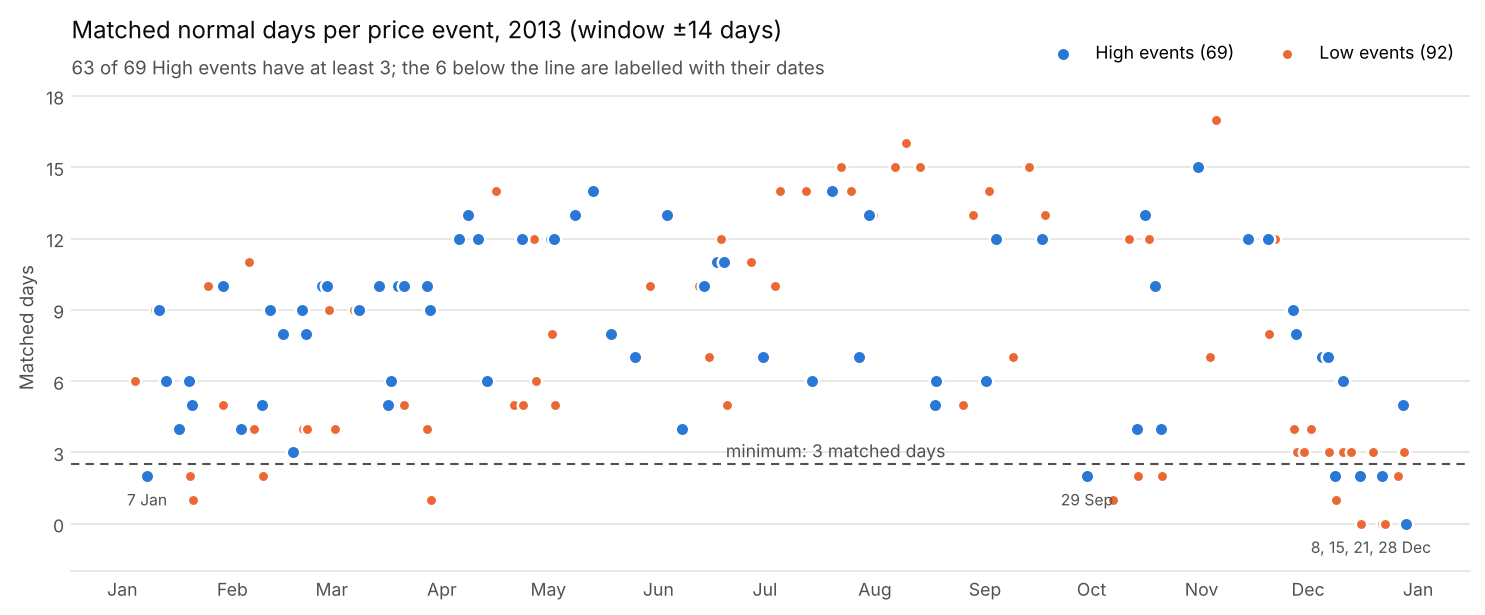

In [7]:
BLUE, ORANGE = "#2a78d6", "#eb6834"          # categorical slots 1 and 2 (validated palette)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator

fig, ax = plt.subplots(figsize=(10, 4.2), dpi=150)
handles = {}
for tariff, colour, size, z in [("Low", ORANGE, 30, 2), ("High", BLUE, 42, 3)]:
    d = counts[counts.tariff == tariff]
    handles[tariff] = ax.scatter(d["start"], d["n_matched_14"], s=size, color=colour, edgecolor="white",
                                 linewidth=1.2, zorder=z, label=f"{tariff} events ({len(d)})")
ax.axhline(MIN_MATCHED - 0.5, color=INK2, linestyle=(0, (4, 3)), linewidth=1, zorder=1)
ax.text(pd.Timestamp("2013-06-20"), MIN_MATCHED - 0.5 + 0.3, "minimum: 3 matched days", color=INK2, fontsize=8.5)

# Label the dropped High events with their dates; events less than 3 weeks apart share one label
drop = counts[high & (counts.n_matched_14 < MIN_MATCHED)].sort_values("start")
groups, current = [], [drop.iloc[0]]
for _, r in drop.iloc[1:].iterrows():
    if (r["start"] - current[-1]["start"]).days < 21:
        current.append(r)
    else:
        groups.append(current); current = [r]
groups.append(current)
for g in groups:
    days = [r["start"] for r in g]
    label = ", ".join(str(t.day) for t in days) + f" {days[-1]:%b}"
    x = days[0] + (days[-1] - days[0]) / 2
    y = min(r["n_matched_14"] for r in g)
    ax.annotate(label, (x, y), xytext=(0, -14), textcoords="offset points", ha="center", fontsize=7.5, color=INK2)

n_dropped = len(drop)
ax.set_title("Matched normal days per price event, 2013 (window ±14 days)", loc="left",
             fontsize=11.5, color=INK, pad=22)
ax.text(0, 1.02, f"{int(usable_high_14.sum())} of {int(high.sum())} High events have at least 3; "
        f"the {n_dropped} below the line are labelled with their dates",
        transform=ax.transAxes, fontsize=9, color=INK2)
ax.set_ylabel("Matched days", color=INK2, fontsize=9)
ax.set_ylim(-2, counts.n_matched_14.max() + 1.5)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=INK2, labelsize=8.5, length=0)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(handles=[handles["High"], handles["Low"]], frameon=False, fontsize=8.5, loc="upper right",
          ncol=2, bbox_to_anchor=(1, 1.12))
fig.tight_layout()
fig.savefig(FIGURES / "stage2_matched_days.png", bbox_inches="tight")
plt.show()

## 8. Worked example: one event and its matched days

A typical evening High event, so anyone can check the rule by eye. Saniah's Stage 3 hand check uses the same idea: the event's half-hours, then the same half-hours on each of these dates.

In [8]:
example = events.merge(counts[["event_id", "n_matched_14"]], on="event_id").query(
    "tariff == 'High' and evening == 1 and hours == 6 and day_type == 'weekday' and n_matched_14 >= 8").iloc[0]
print(f"{example.event_id}: {example.start:%a %d %b %Y %H:%M} to {example.end:%H:%M} GMT, "
      f"slots {example.first_slot}–{example.first_slot + example.n_slots - 1}, {example.day_type}")

ex = matched[matched.event_id == example.event_id].copy()
ex["matched_date"] = (example.start.normalize() + pd.to_timedelta(ex.shift_days, unit="D")).dt.strftime("%a %d %b")
ex["slots"] = [f"{example.first_slot + 48 * k}–{example.first_slot + 48 * k + example.n_slots - 1}" for k in ex.shift_days]
ex["in_main_window"] = ex.shift_days.abs() <= MAIN_WINDOW
ex.reset_index(drop=True)

H026: Wed 20 Feb 2013 17:00 to 23:00 GMT, slots 2434–2445, weekday


,event_id,shift_days,matched_date,slots,in_main_window
0,H026,-20,Thu 31 Jan,1474–1485,False
1,H026,-19,Fri 01 Feb,1522–1533,False
2,H026,-16,Mon 04 Feb,1666–1677,False
3,H026,-14,Wed 06 Feb,1762–1773,True
4,H026,-8,Tue 12 Feb,2050–2061,True
5,H026,-7,Wed 13 Feb,2098–2109,True
6,H026,-6,Thu 14 Feb,2146–2157,True
7,H026,-1,Tue 19 Feb,2386–2397,True
8,H026,5,Mon 25 Feb,2674–2685,True
9,H026,12,Mon 04 Mar,3010–3021,True


## 9. Save the reported numbers → `results/results.json`

These counts go into the report (data section and exclusions), so they are written by code under the key `p1_events`, next to Saniah's `p1_matrix` and `p1_event_scores_*` keys. Existing keys in the file are kept.

In [9]:
def save_section(key, values, path=RESULTS / "results.json"):
    data = json.loads(path.read_text()) if path.exists() else {}
    data[key] = values
    path.write_text(json.dumps(data, indent=2, default=str))


p1_events = {
    "tariff_half_hours": tariffs["price"].value_counts().to_dict(),
    "n_events_high": int(high.sum()),
    "n_events_low": int(low.sum()),
    "high_event_lengths_hours": {str(k): int(v) for k, v in high_lengths.items()},
    "high_share_17_to_23": round(float(((tariffs.price == "High") & tariffs.time.dt.hour.between(17, 22)).sum()
                                       / (tariffs.price == "High").sum()), 4),
    "off_grid_dates": sorted(set(events.loc[events.off_grid, "start"].dt.strftime("%Y-%m-%d"))),
    "n_off_grid_events": int(events.off_grid.sum()),
    "normal_days": len(normal_days),
    "normal_days_by_type": normal_days["day_type"].value_counts().to_dict(),
    "high_dropped_w14": dropped_high_14,
    "low_dropped_w14": int((low & (counts.n_matched_14 < MIN_MATCHED)).sum()),
    "high_usable_w14": int(usable_high_14.sum()),
    "low_usable_w14": int((low & (counts.n_matched_14 >= MIN_MATCHED)).sum()),
    "median_matched_days_high_w14": float(counts.loc[usable_high_14, "n_matched_14"].median()),
    "high_dropped_w21": dropped_high_21,
    "low_dropped_w21": int((low & (counts.n_matched_21 < MIN_MATCHED)).sum()),
    "high_dropped_w7": int((high & (n7 < MIN_MATCHED)).sum()),
}
save_section("p1_events", p1_events)
print(json.dumps(p1_events, indent=2))

{
  "tariff_half_hours": {
    "Normal": 15072,
    "Low": 1660,
    "High": 788
  },
  "n_events_high": 69,
  "n_events_low": 92,
  "high_event_lengths_hours": {
    "3.0": 26,
    "4.0": 1,
    "6.0": 34,
    "12.0": 7,
    "24.0": 1
  },
  "high_share_17_to_23": 0.5178,
  "off_grid_dates": [
    "2013-01-29",
    "2013-02-09",
    "2013-03-21"
  ],
  "n_off_grid_events": 8,
  "normal_days": 212,
  "normal_days_by_type": {
    "weekday": 144,
    "weekend": 68
  },
  "high_dropped_w14": [
    "2013-01-07",
    "2013-09-29",
    "2013-12-08",
    "2013-12-15",
    "2013-12-21",
    "2013-12-28"
  ],
  "low_dropped_w14": 15,
  "high_usable_w14": 63,
  "low_usable_w14": 77,
  "median_matched_days_high_w14": 9.0,
  "high_dropped_w21": [
    "2013-12-21",
    "2013-12-28"
  ],
  "low_dropped_w21": 5,
  "high_dropped_w7": 16
}


## 10. Stage 0 task: does the regression plan work with these events?

`decisions.md` §11 fixes the Stage 6 regression: `effect ~ evening + hours + winter + low_before`, one row per usable High event, leave-one-month-out cross-validation, and drop `hours` if any VIF > 5. The guideline (§10, item 4) asks Javed to confirm this before Stage 6.

The checks below use **only the event features** (when an event starts, how long it lasts), never the electricity effect, so they don't break the results gate.

In [10]:
PREDICTORS = ["evening", "hours", "winter", "low_before"]
reg = events[usable_high_14.to_numpy()].sort_values("start").reset_index(drop=True)
X = reg[PREDICTORS].astype(float)
print(f"Rows for the regression: {len(reg)} usable High events, {len(PREDICTORS) + 1} parameters "
      f"(≈{len(reg) / (len(PREDICTORS) + 1):.0f} events per parameter)\n")
print("How often each feature occurs:")
for c in ["evening", "winter", "low_before"]:
    print(f"  {c:<11} 1: {int(X[c].sum()):>2}   0: {int((X[c] == 0).sum()):>2}")
print("  hours      ", reg["hours"].value_counts().sort_index().to_dict())


def vif_table(X):
    # VIF_j = 1 / (1 − R²) from regressing predictor j on the others (with an intercept);
    # gives the same numbers as statsmodels' variance_inflation_factor on add_constant(X).
    out = {}
    for c in X.columns:
        y = X[c].to_numpy()
        Z = np.column_stack([np.ones(len(X)), X.drop(columns=c).to_numpy()])
        beta, *_ = np.linalg.lstsq(Z, y, rcond=None)
        resid = y - Z @ beta
        r2 = 1 - resid @ resid / ((y - y.mean()) @ (y - y.mean()))
        out[c] = round(float(1 / (1 - r2)), 2)
    return out


vifs = vif_table(X)
print("\nVariance inflation factors:", vifs)
print("→", "all ≤ 5, so `hours` stays in the model as planned." if max(vifs.values()) <= 5
      else "a VIF is above 5, so drop `hours` (pre-agreed rule) and log it.")

folds = []
for m in sorted(reg.month.unique()):
    train = reg[reg.month != m]
    Z = np.column_stack([np.ones(len(train)), train[PREDICTORS].to_numpy(float)])
    folds.append({"held_out_month": m, "test_events": int((reg.month == m).sum()), "train_events": len(train),
                  "constant_predictors": [c for c in PREDICTORS if train[c].nunique() < 2] or "none",
                  "all_5_estimable": np.linalg.matrix_rank(Z) == 5})
folds = pd.DataFrame(folds)
print("\nLeave-one-month-out folds:")
print(folds.to_string(index=False))
print("→", "every fold can estimate all 5 parameters." if folds.all_5_estimable.all()
      else "some folds can't estimate every parameter: drop that predictor in that fold only, and note it.")
print("\nNote: there is one 24-hour event and a few 12-hour ones; expect them to show up in the Cook's distance check.")

Rows for the regression: 63 usable High events, 5 parameters (≈13 events per parameter)

How often each feature occurs:
  evening     1: 29   0: 34
  winter      1: 37   0: 26
  low_before  1: 22   0: 41
  hours       {3.0: 25, 4.0: 1, 6.0: 31, 12.0: 5, 24.0: 1}

Variance inflation factors: {'evening': 1.61, 'hours': 1.03, 'winter': 1.24, 'low_before': 1.87}
→ all ≤ 5, so `hours` stays in the model as planned.

Leave-one-month-out folds:
 held_out_month  test_events  train_events constant_predictors  all_5_estimable
              1            6            57                none             True
              2            9            54                none             True
              3            8            55                none             True
              4            5            58                none             True
              5            6            57                none             True
              6            6            57                none             Tru

**Conclusion for the tracker:** the regression in `decisions.md` §11 can be coded exactly as written. No change to log.

## 11. Handing off to Saniah (Stage 3)

The four files in `results/` follow the column contracts in `BLUEPRINT.md` §7:

- `events.csv`: `event_id, tariff, start, first_slot, n_slots, end, hours, day_type, off_grid, low_before, evening, month, winter`
- `normal_days.csv`: `date, day_type`
- `matched_days.csv`: `event_id, shift_days` (one row per matched day, |shift| ≤ 21). The matched window is `first_slot + 48 × shift_days`, with the same length as the event. Filter `abs(shift_days) <= 14` for the main analysis.
- `matched_counts.csv`: `event_id, tariff, start, n_matched_14, n_matched_21`

To put this into the repository, copy `src/01_events.py` and `src/02_matched_days.py` into `src/`. They contain the same code as this notebook and write the same files, so `run_all.py` can call them.